In [66]:
#setup
import pandas as pd
import os
import configparser
import geopandas as gpd
from shapely.geometry import Point
import seaborn as sns

import matplotlib.pyplot as plt

In [27]:
#set filepaths
project_root = os.path.abspath(os.getcwd())
root = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
config_file =  os.path.join(root, 'config.cfg')

# geodata for shapefiles
config = configparser.ConfigParser()
config.read(config_file)
gdata_root = config['geodata']['path']

In [28]:
# read London shapefile
london = gpd.read_file(os.path.join(gdata_root, 'london-shapefiles\\london-no-river.geojson'))

# load river shapefile
river = gpd.GeoDataFrame.from_file(os.path.join(gdata_root, 'london-shapefiles\\river-thames-clipped.geojson'))

## Data processing

In [2]:
#load data
df = pd.read_csv("Borough_tree_list_2025Nov.csv")

# convert into geodataframe
geometry = [Point(xy) for xy in zip(df["lon"].astype(float), df["lat"].astype(float))]
gdf = gpd.GeoDataFrame(df, crs="EPSG:4326", geometry=geometry)

In [ ]:
gdf_m = gdf.to_crs(epsg=27700).copy()  # British National Grid, metres
gdf_m["x"] = gdf_m.geometry.x        
gdf_m["y"] = gdf_m.geometry.y   

In [11]:
gdf["location"].value_counts()

location
Highways    97408
Other       28329
Parks       24749
Housing      3335
Name: count, dtype: int64

In [22]:
import numpy as np
from scipy.spatial import cKDTree

R = 100          # search radius in metres
SEP = 2 * R      # hotspots must be at least this far apart so they don't overlap

cherries = gdf[(gdf["gla_name"] == "Cherry") & (gdf["location"].isin(["Highways"]))].to_crs(32630).reset_index(drop=True)
xy = np.column_stack([cherries.geometry.x, cherries.geometry.y])
tree = cKDTree(xy)

# 1. trees within 100 m of each tree (including itself)
cherries["n_100m"] = tree.query_ball_point(xy, r=R, return_length=True)

# 2. greedy selection: take the densest tree, discard everything within 200 m, repeat
order = np.argsort(-cherries["n_100m"].values)
available = np.ones(len(cherries), dtype=bool)
picked = []
for i in order:
    if not available[i]:
        continue
    picked.append(i)
    available[tree.query_ball_point(xy[i], r=SEP)] = False
    if len(picked) == 5:
        break

top = cherries.iloc[picked].copy()

# 3. centre each hotspot on the mean of the trees around it, and compute density
centres = [xy[tree.query_ball_point(xy[i], r=R)].mean(axis=0) for i in picked]
top["geometry"] = gpd.points_from_xy(*np.array(centres).T)
top["borough"] = cherries.loc[picked, "borough"].values

# convert into geodataframe
geometry = [Point(xy) for xy in zip(top["lon"].astype(float), top["lat"].astype(float))]
top_gdf = gpd.GeoDataFrame(top, crs="EPSG:4326", geometry=geometry)

print(top[["borough", "n_100m",]])

                      borough  n_100m
24119  Hammersmith and Fulham      54
66076                 Bromley      53
51088               Redbridge      52
66356                 Bromley      52
25485  Kensington and Chelsea      51


In [25]:
import numpy as np
from scipy.spatial import cKDTree

R = 100          # search radius in metres
SEP = 2 * R      # hotspots must be at least this far apart so they don't overlap

cherries = gdf[(gdf["gla_name"] == "Cherry") & (gdf["location"].isin(["Parks"]))].to_crs(32630).reset_index(drop=True)
xy = np.column_stack([cherries.geometry.x, cherries.geometry.y])
tree = cKDTree(xy)

# 1. trees within 100 m of each tree (including itself)
cherries["n_100m"] = tree.query_ball_point(xy, r=R, return_length=True)

# 2. greedy selection: take the densest tree, discard everything within 200 m, repeat
order = np.argsort(-cherries["n_100m"].values)
available = np.ones(len(cherries), dtype=bool)
picked = []
for i in order:
    if not available[i]:
        continue
    picked.append(i)
    available[tree.query_ball_point(xy[i], r=SEP)] = False
    if len(picked) == 5:
        break

top_parks = cherries.iloc[picked].copy()

# 3. centre each hotspot on the mean of the trees around it, and compute density
centres = [xy[tree.query_ball_point(xy[i], r=R)].mean(axis=0) for i in picked]
top_parks["geometry"] = gpd.points_from_xy(*np.array(centres).T)
top_parks["borough"] = cherries.loc[picked, "borough"].values

# convert into geodataframe
geometry = [Point(xy) for xy in zip(top_parks["lon"].astype(float), top_parks["lat"].astype(float))]
top_parks_gdf = gpd.GeoDataFrame(top_parks, crs="EPSG:4326", geometry=geometry)

print(top_parks[["borough", "n_100m",]])

              borough  n_100m
5739         Haringey     284
16822  Waltham Forest     227
7412          Hackney     181
4958         Haringey     146
16887  Waltham Forest     131


## Data checks

In [68]:
gdf["location"].value_counts()

location
Highways    97408
Other       28329
Parks       24749
Housing      3335
Name: count, dtype: int64

In [67]:
len(gdf[(gdf["gla_name"] == "Cherry")])

153821

In [65]:
top

,borough,lat,lon,uniqueid,taxon_species,common_name,taxon_genus,common_genus,gla_name,taxon_family,maintainer,location,climate_suitability,cs_confidence,age_cat,canopy_m,height_m,girth_dbh,geometry,n_100m
24119,Hammersmith and Fulham,51.468970,-0.187571,302865,Prunus,Cherry,Prunus,Cherry,Cherry,Rosaceae,LB Hammersmith & Fulham,Highways,Low,Low,Not provided,Not recorded,Not recorded,Not recorded,POINT (695320.436 5705730.033),54
66076,Bromley,51.389580,0.057647,779309,Prunus laurocerasus,Cherry Laurel,Prunus,Cherry,Cherry,Rosaceae,LB Bromley,Highways,Low,Low,Not provided,Not recorded,Not recorded,Not recorded,POINT (712716.897 5697578.364),53
51088,Redbridge,51.570808,0.053815,593270,Prunus cerasifera,Cherry Plum,Prunus,Cherry,Cherry,Rosaceae,LB Redbridge,Highways,Moderate,High,Not provided,Not recorded,Not recorded,15 cm,POINT (711608.749 5717716.467),52
66356,Bromley,51.404928,-0.038213,779703,Prunus serrulata,Japanese Cherry,Prunus,Cherry,Cherry,Rosaceae,LB Bromley,Highways,Low,Low,Not provided,Not recorded,Not recorded,Not recorded,POINT (705994.210 5699021.076),52
25485,Kensington and Chelsea,51.520581,-0.227152,304231,Prunus,Cherry,Prunus,Cherry,Cherry,Rosaceae,RB Kensington & Chelsea,Highways,Low,Low,Not provided,Not recorded,4 m,12 cm,POINT (692387.067 5711362.953),51


In [58]:
gdf[(gdf["gla_name"] == "Cherry")]["borough"].nunique()

33

In [55]:
gdf[(gdf["gla_name"] == "Cherry")]["borough"].value_counts()

borough
Redbridge                 11309
Bromley                   11164
Ealing                     9720
Enfield                    9382
Barnet                     9360
Wandsworth                 6695
Waltham Forest             6642
Harrow                     6443
Southwark                  6403
Islington                  5253
Brent                      4976
Greenwich                  4879
Hounslow                   4874
Hillingdon                 4652
Merton                     4605
Hackney                    4568
Lewisham                   4543
Haringey                   4274
Newham                     4274
Lambeth                    4264
Richmond upon Thames       3839
Bexley                     3466
Tower Hamlets              3131
Westminster                3045
Camden                     2756
Kingston upon Thames       2659
Barking and Dagenham       2234
Hammersmith and Fulham     2194
Kensington and Chelsea     1366
Havering                    368
Sutton                      265


## Visualisation

In [56]:
#colours
from matplotlib.colors import LinearSegmentedColormap

cherry_cmap = LinearSegmentedColormap.from_list(
    "cherry", ["#FCE4F1", "#F4A6D0", "#E3439A", "#A3166F"]   
)
clrs = {"bg": "#87466D", "london": "#FBDFEF",  "river": "#87466D" }

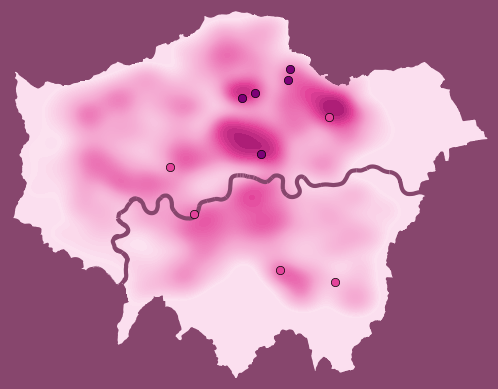

In [57]:
fig, ax = plt.subplots()
fig.set_facecolor(clrs["bg"])

# add london and river for reference  ---------------------------
london.to_crs(epsg=27700).plot(ax=ax, color=clrs["london"], 
                               edgecolor=clrs["river"], linewidth=2, zorder=1)
river.to_crs(epsg=27700).plot(ax=ax, color=clrs["river"],
                               edgecolor=clrs["river"], linewidth=3, zorder=3, alpha=1)

#Density plot clipped to london outline
import numpy as np
from matplotlib.path import Path
from matplotlib.patches import PathPatch

# London outline in the same CRS as the density (27700)
london_geom = london.to_crs(epsg=27700).geometry.unary_union

def geom_to_path(geom):
    """Shapely (Multi)Polygon -> matplotlib Path (outer rings only)."""
    polys = geom.geoms if hasattr(geom, "geoms") else [geom]
    verts, codes = [], []
    for p in polys:
        xy = np.asarray(p.exterior.coords)
        verts.extend(xy)
        codes.extend([Path.MOVETO] + [Path.LINETO] * (len(xy) - 2) + [Path.CLOSEPOLY])
    return Path(verts, codes)

clip_patch = PathPatch(geom_to_path(london_geom), transform=ax.transData)

# plot the density, remembering which artists belong to it
n_before = len(ax.collections)
sns.kdeplot(
    data=gdf_m[gdf_m["gla_name"] == "Cherry"],
    x="x", y="y", fill=True, levels=60, thresh=0.05,
    cmap=cherry_cmap, alpha=1, antialiased=False, ax=ax, zorder=2,
)
for coll in ax.collections[n_before:]:      # only the density layers
    coll.set_clip_path(clip_patch)

# frame the map on London instead of the whole density extent
minx, miny, maxx, maxy = london_geom.bounds
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)
ax.set_aspect("equal")


#plot top 10 hotspots by location
top_gdf.to_crs(epsg=27700).plot(ax=ax, color="#E3439A", zorder=4, 
                                edgecolor="black", linewidth=0.5)
top_parks_gdf.to_crs(epsg=27700).plot(ax=ax, color="#7D0177" ,zorder=4, 
                                      edgecolor="black", linewidth=0.5)

ax.set_aspect("equal")
ax.axis("off")

#export
#plt.savefig("cherry-trees.svg")

plt.show()

## Playground

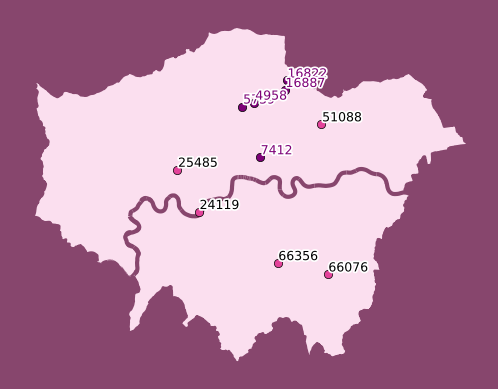

In [63]:
fig, ax = plt.subplots()
fig.set_facecolor(clrs["bg"])

# add london and river for reference  ---------------------------
london.to_crs(epsg=27700).plot(ax=ax, color=clrs["london"], 
                               edgecolor=clrs["river"], linewidth=2, zorder=1)
river.to_crs(epsg=27700).plot(ax=ax, color=clrs["river"],
                               edgecolor=clrs["river"], linewidth=3, zorder=3, alpha=1)


#plot top 10 hotspots by location
top_gdf.to_crs(epsg=27700).plot(ax=ax, color="#E3439A", zorder=4, 
                                edgecolor="black", linewidth=0.5)
top_parks_gdf.to_crs(epsg=27700).plot(ax=ax, color="#7D0177" ,zorder=4, 
                                      edgecolor="black", linewidth=0.5)


import matplotlib.patheffects as pe

def label_points(gdf, ax, color="black", dx=100, dy=0):
    g = gdf.to_crs(epsg=27700)
    for idx, row in g.iterrows():          # idx is the index value
        ax.annotate(
            str(idx),
            xy=(row.geometry.x, row.geometry.y),
            xytext=(row.geometry.x + dx, row.geometry.y + dy),
            fontsize=9, color=color, zorder=5,
            ha="left", va="bottom",
            path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
        )

label_points(top_gdf, ax)
label_points(top_parks_gdf, ax, color="#7D0177")



ax.set_aspect("equal")
ax.axis("off")

#export

plt.show()

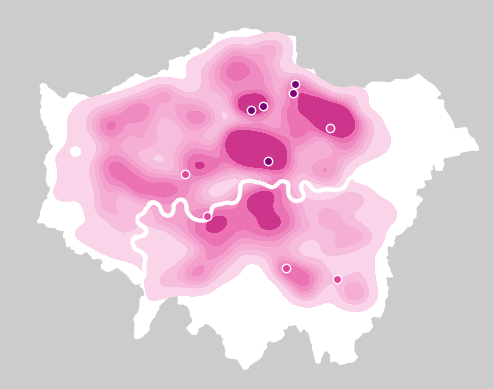

In [45]:
fig, ax = plt.subplots()
fig.set_facecolor(clrs["bg"])

# add london and river for reference  ---------------------------
london.to_crs(epsg=27700).plot(ax=ax, color=clrs["london"], 
                               edgecolor=clrs["river"], linewidth=2, zorder=1)
river.to_crs(epsg=27700).plot(ax=ax, color=clrs["river"],
                               edgecolor=clrs["river"], linewidth=3, zorder=3, alpha=1)

sns.kdeplot(
    data=gdf_m[gdf_m["gla_name"]=="Cherry"],
    x="x", y="y", fill=True, levels=8,
    thresh=0.05, cmap=cherry_cmap, alpha=1, ax=ax,
    zorder=2, antialiased=False,
)

#plot top 10 hotspots by location
top_gdf.to_crs(epsg=27700).plot(ax=ax, color="#E3439A", zorder=4, edgecolor="white", linewidth=1)
top_parks_gdf.to_crs(epsg=27700).plot(ax=ax, color="#7D0177" ,zorder=4, edgecolor="white", linewidth=1)

ax.set_aspect("equal")
ax.axis("off")

plt.show()